**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**20 | HARTH Minority-Class and Source Data Quality Audit**

![Source quality and minority-class audit workflow](https://raw.githubusercontent.com/RezaSaadatyar/human-movement-intelligence/main/wearable_activity_recognition/images/20_workflow.svg)

**Objective:** Examine how activity prevalence, annotation bouts, timestamp continuity, sampling limits and participant coverage affect the available evidence for the eight-class HARTH task.

**Dataset:** Pinned HARTH v2.0 recordings for 29 Development participants, excluding reserved Test IDs S023 and S032.

**Notebook Scope:** Audit source labels, eligible windows, rejection reasons and six-axis signal characteristics, with particular attention to Shuffling and stair activities. No model or scaler is fitted. These descriptive checks do not establish the cause of model errors or certify sensor and annotation quality.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")
%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content
/content/human-movement-intelligence


**01. Imports and Source-Audit Environment**

In [2]:
# ================= 01. Imports and Source-Audit Environment ==================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")

# ----------------- 2. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 3. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

plot_style(font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11, legend_size=10,
    figure_dpi=100, figure_size=(9, 4))

# ---------------- 4. HARTH Source and Quality Audit Utilities ----------------
from core.output_download import download_outputs_from_colab
from harth_data import HARTH_SUBJECTS, ACTIVITY_NAMES, SENSOR_COLUMNS, HARTH_REVISION
from harth_quality import audit_harth_development_sources
from core.sampling_audit import audit_temporal_sampling

# -------------- 6. Development Cohort and Source Configuration ---------------
RESERVED_TEST = {"S023", "S032"}
SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)
CLASSES = tuple(range(1, 9))
DATA_DIR = root / "data/raw/harth_v2"

# ----------------------- 7. Reusable Research Output Directory --------------
output_dir = root / "wearable_activity_recognition" / "output"
output_dir.mkdir(parents=True, exist_ok=True)

# ---------------- 7. Source Audit Integrity and Setup Summary ----------------
assert len(SUBJECTS) == 29
assert not (set(SUBJECTS) & RESERVED_TEST)

print("STAGE 20 | HARTH SOURCE QUALITY AUDIT")
print("=" * 65)
print("Development subjects:", len(SUBJECTS))
print("Documented target activity codes:", CLASSES)
print("Pinned source revision:", HARTH_REVISION)
print("Research output directory:", output_dir)
print("Reserved Test subjects excluded:", sorted(RESERVED_TEST))


STAGE 20 | HARTH SOURCE QUALITY AUDIT
Development subjects: 29
Documented target activity codes: (1, 2, 3, 4, 5, 6, 7, 8)
Pinned source revision: dad2cfbe89a26f72f19770419469ac037de200df
Research output directory: /content/human-movement-intelligence/wearable_activity_recognition/output
Reserved Test subjects excluded: ['S023', 'S032']


**02. Audit Each Development Recording**

Load each pinned recording separately, preserve source labels and sensor channels, and inspect continuity at the nominal 50 Hz rate. Construct 100-sample windows with a 50-sample stride, retaining only single-labelled, time-continuous candidates. Exclude out-of-task codes after segmentation.

Record sample counts, mutually exclusive rejection reasons, retained windows, annotation-bout summaries and channel statistics by participant.

In [3]:
# =================== 02. Audit Each Development Recording ====================

# ---------------- 1. Audit Individual Development Recordings -----------------
(overview, raw_codes, window_codes, metadata,
 bouts, channels, examples) = audit_harth_development_sources(
    subjects=SUBJECTS, data_dir=DATA_DIR, task_classes=CLASSES,
    window_size=100, step_size=50, sampling_rate=50,
    reserved_subjects=RESERVED_TEST,
)

# ------------------- 2. Reconcile Source and Window Counts -------------------
display(overview.sort_values("subject_id"))
print("\n" + "=" * 65)
print("DEVELOPMENT SOURCE ACCOUNTING")
print("=" * 65)
print("Source participants:", overview["subject_id"].nunique())
print("Original CSV rows:", f'{overview["raw_samples"].sum():,}')
print("All valid pure-label windows:", f'{overview["retained_pure_time_safe"].sum():,}')
print("Eight-class eligible windows:", f'{len(metadata):,}')
print("Windows excluded after segmentation:", f'{overview["excluded_after_windowing"].sum():,}')

assert len(metadata) == 132397, "Investigate source/pipeline mismatch with Stage 08."
assert set(metadata["subject_id"]) == set(SUBJECTS)


Downloaded 59,108,125 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Audited S006: 408,709 source rows, 6,708 task windows, 733 excluded accepted windows
Downloaded 60,603,857 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Audited S008: 418,989 source rows, 7,392 task windows, 172 excluded accepted windows
Downloaded 22,408,603 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidate

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_quality.py:269: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  source, names = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Audited S030: 245,994 source rows, 3,312 task windows, 23 excluded accepted windows
Downloaded 22,728,229 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S031.csv


/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_quality.py:269: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  source, names = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Audited S031: 269,560 source rows, 2,798 task windows, 1,613 excluded accepted windows
Downloaded 16,070,724 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Audited S033: 201,688 source rows, 3,687 task windows, 0 excluded accepted windows
Downloaded 15,031,875 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Audited S034: 188,202 source rows, 3,351 task windows, 0 excluded accepted windows
Downl

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_quality.py:269: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  source, names = load_harth_subject(path, allow_unmapped_labels=True)


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Audited S037: 206,379 source rows, 3,204 task windows, 264 excluded accepted windows
Downloaded 15,185,213 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Audited S038: 184,992 source rows, 3,007 task windows, 348 excluded accepted windows


,subject_id,raw_samples,candidate_windows,retained_pure_time_safe,eligible_eight_class_windows,excluded_after_windowing,undocumented_raw_samples,rejected_label_only,rejected_time_only,rejected_both,nonpositive_intervals,long_intervals,median_positive_interval_seconds
0,S006,408709,8173,7441,6708,733,0,663,45,24,0,38,0.02
1,S008,418989,8378,7564,7392,172,0,740,8,66,0,38,0.02
2,S009,154464,3088,2885,201,2684,0,191,6,6,0,6,0.02
3,S010,351649,7031,6077,6077,0,0,930,11,13,0,13,0.02
4,S012,382414,7647,7309,7309,0,0,276,16,46,0,32,0.02
5,S013,369077,7380,6451,6402,49,0,832,29,68,0,54,0.02
6,S014,366487,7328,6409,6299,110,0,791,28,100,0,69,0.02
7,S015,418392,8366,7626,7453,173,0,668,14,58,0,36,0.02
8,S016,355418,7107,6484,6272,212,0,554,20,49,0,35,0.02
9,S017,366609,7331,6841,6678,163,0,414,16,60,0,38,0.02



DEVELOPMENT SOURCE ACCOUNTING
Source participants: 29
Original CSV rows: 8,006,741
All valid pure-label windows: 144,105
Eight-class eligible windows: 132,397
Windows excluded after segmentation: 11,708


**03. Distinguish Documented and Undocumented Source Codes**

Report raw-row and eligible-window support for each original source code. Eight documented activities form the classification task; other documented activities, including cycling, are distinct from undocumented codes. Do not assign unsupported activity names to `10`, `11` or `17`.

In [4]:
# ========= 03. Distinguish Documented and Undocumented Source Codes ==========

# --------------------- 1. Inspect Original Source Labels ---------------------
source_labels = raw_codes.groupby(
    ["source_code", "source_activity", "in_eight_class_task"],
    as_index=False
)["source_samples"].sum().sort_values("source_code")

display(source_labels)
excluded_codes = raw_codes.loc[
    ~raw_codes["in_eight_class_task"]
].sort_values(["source_code", "subject_id"])

display(excluded_codes[[
    "subject_id", "source_code", "source_activity",
    "source_samples", "documented_source_code"
]])

# ----------------- 2. Report Excluded and Undocumented Codes -----------------
post_window = window_codes.groupby(
    ["source_code", "source_activity", "in_eight_class_task"],
    as_index=False
)["accepted_pure_windows"].sum().sort_values("source_code")

display(post_window)
unknown_codes = sorted(
    raw_codes.loc[~raw_codes["documented_source_code"], "source_code"].unique().tolist()
)

print("Undocumented source codes observed:", unknown_codes)
print("Unknown-code semantic interpretation performed: NO")


,source_code,source_activity,in_eight_class_task,source_samples
0,1,Walking,True,1553898
1,2,Running,True,323143
2,3,Shuffling,True,310523
3,4,Stairs ascending,True,91133
4,5,Stairs descending,True,85404
5,6,Standing,True,1210084
6,7,Sitting,True,3253551
7,8,Lying,True,555840
8,10,UNDOCUMENTED source code,False,3522
9,11,UNDOCUMENTED source code,False,1892


,subject_id,source_code,source_activity,source_samples,documented_source_code
210,S030,10,UNDOCUMENTED source code,1884,False
219,S031,10,UNDOCUMENTED source code,216,False
254,S037,10,UNDOCUMENTED source code,1422,False
211,S030,11,UNDOCUMENTED source code,1774,False
220,S031,11,UNDOCUMENTED source code,118,False
7,S006,13,Cycling seated,25040,True
16,S008,13,Cycling seated,7548,True
25,S009,13,Cycling seated,120101,True
51,S013,13,Cycling seated,2764,True
61,S014,13,Cycling seated,5570,True


,source_code,source_activity,in_eight_class_task,accepted_pure_windows
0,1,Walking,True,26979
1,2,Running,True,6305
2,3,Shuffling,True,1946
3,4,Stairs ascending,True,1332
4,5,Stairs descending,True,1066
5,6,Standing,True,19218
6,7,Sitting,True,64644
7,8,Lying,True,10907
8,10,UNDOCUMENTED source code,False,20
9,11,UNDOCUMENTED source code,False,15


Undocumented source codes observed: [10, 11, 17]
Unknown-code semantic interpretation performed: NO


**04. Compare Activity Windows and Participant Support**

Summarise each activity's retained window count and the number of distinct participants contributing windows. Overlapping windows are correlated, so window volume must not be interpreted as the number of independent observations. Represent absent participant–activity combinations explicitly as zero.

,Walking,Running,Shuffling,Stairs ascending,Stairs descending,Standing,Sitting,Lying
subject_id,,,,,,,,
S006,315,0,59,19,26,998,5036,255
S008,294,0,259,10,11,977,5841,0
S009,91,0,0,7,9,94,0,0
S010,3263,0,229,93,47,1519,926,0
S012,170,39,47,64,32,370,6215,372
S013,501,65,378,42,26,809,4449,132
S014,342,41,92,70,42,827,4715,170
S015,900,50,36,99,72,1161,3886,1249
S016,663,48,113,5,30,850,3784,779


,activity,eligible_windows,supporting_subjects,window_share_pct,subject_coverage_pct
0,Walking,26979,29,20.38,100.00
1,Running,6305,19,4.76,65.52
2,Shuffling,1946,28,1.47,96.55
3,Stairs ascending,1332,26,1.01,89.66
4,Stairs descending,1066,25,0.81,86.21
5,Standing,19218,29,14.52,100.00
6,Sitting,64644,28,48.83,96.55
7,Lying,10907,23,8.24,79.31


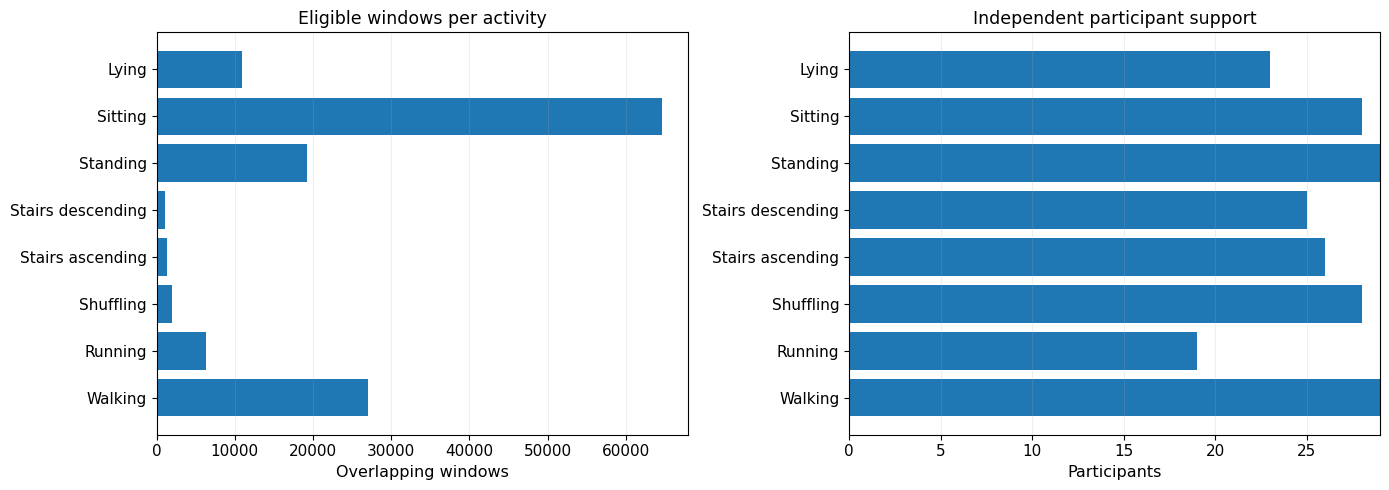

In [5]:
# =========== 04. Compare Activity Windows and Participant Support ============

# ------------------- 1. Compute Participant-Class Coverage -------------------
coverage = pd.crosstab(metadata["subject_id"], metadata["label"]).reindex(
    index=SUBJECTS, columns=CLASSES, fill_value=0
).astype(int)
coverage.columns = [ACTIVITY_NAMES[c] for c in CLASSES]

display(coverage)

# ----------------------- 2. Summarise Activity Support -----------------------
class_summary = pd.DataFrame({
    "activity": coverage.columns,
    "eligible_windows": coverage.sum(axis=0).to_numpy(),
    "supporting_subjects": (coverage > 0).sum(axis=0).to_numpy(),
})
class_summary["window_share_pct"] = (
    class_summary["eligible_windows"] / class_summary["eligible_windows"].sum() * 100
)

class_summary["subject_coverage_pct"] = (
    class_summary["supporting_subjects"] / len(SUBJECTS) * 100
)

display(class_summary.round(2))

# ------------------ 3. Visualise Source Window Distribution ------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].barh(class_summary["activity"], class_summary["eligible_windows"])
axes[0].set(title="Eligible windows per activity", xlabel="Overlapping windows")
axes[1].barh(class_summary["activity"], class_summary["supporting_subjects"])
axes[1].set(title="Independent participant support", xlabel="Participants", xlim=(0,29))
for ax in axes:
    ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "20_activity_window_and_subject_support.png")
plt.show()


**05. Visualise Activity Coverage Across Participants**

Use window-count and within-participant percentage heatmaps to distinguish absolute activity volume from each participant's activity composition. Neither view estimates activity prevalence in the wider population.

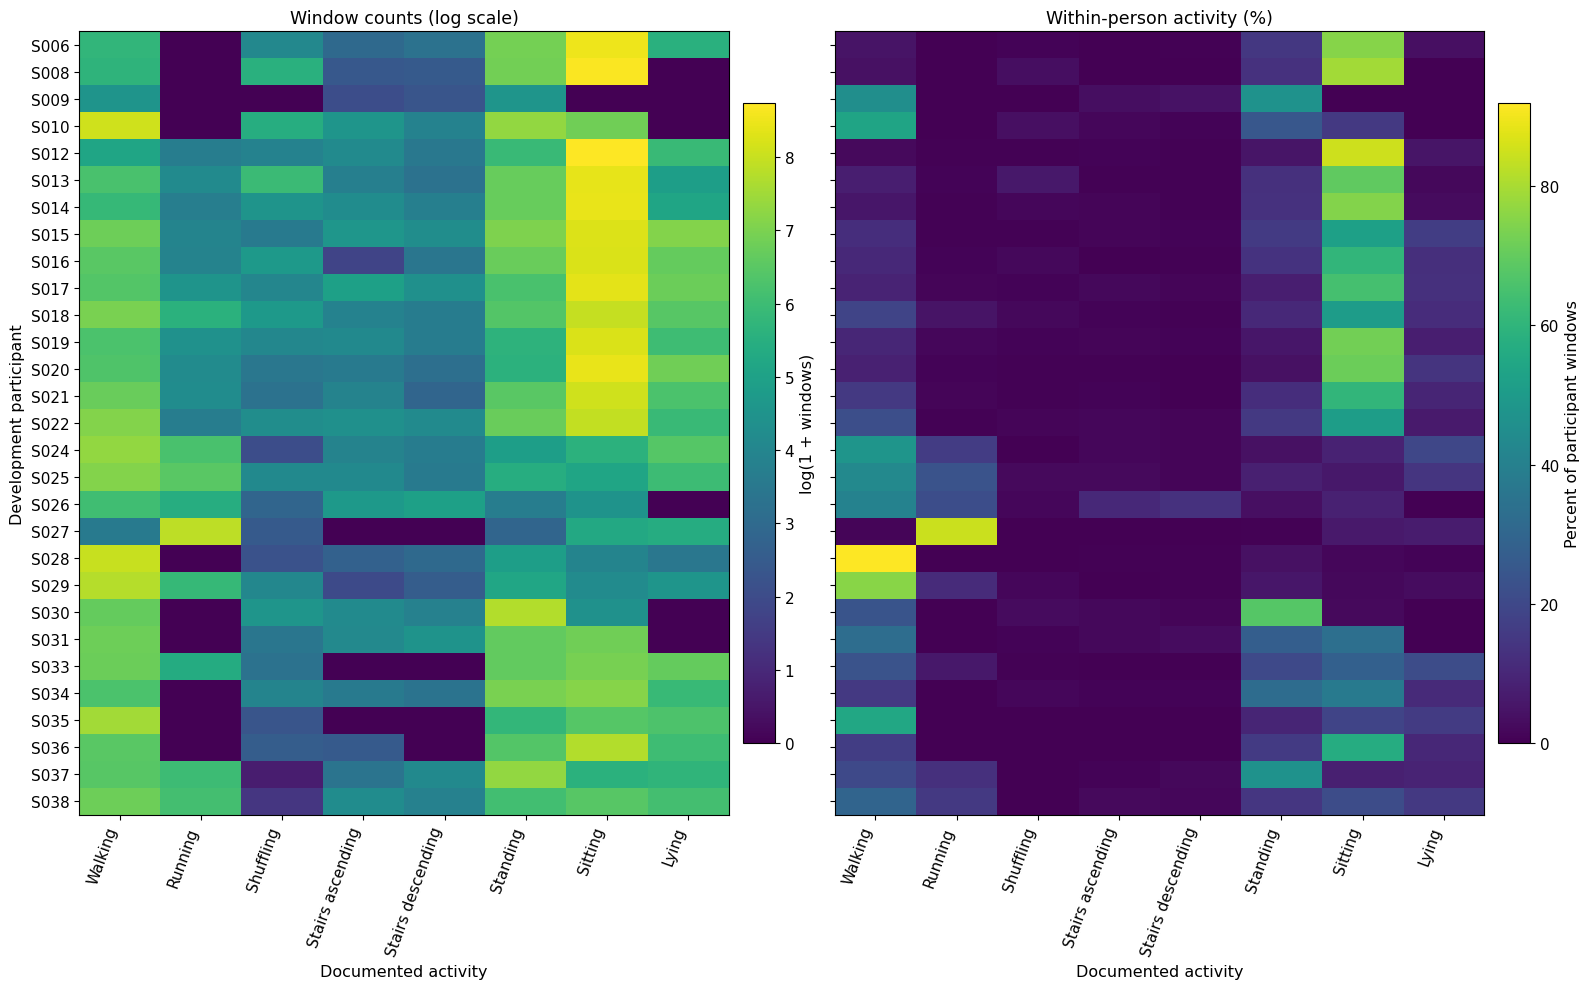

In [6]:
# ============ 05. Visualise Activity Coverage Across Participants ============

# ----------- 1. Calculate Within-Participant Activity Proportions ------------
fractions = coverage.div(coverage.sum(axis=1), axis=0).mul(100)

# ---------------- 2. Visualise Absolute and Relative Coverage ----------------
fig, axes = plt.subplots(1, 2, figsize=(16, 10), sharey=True)

maps = [
    (np.log1p(coverage.to_numpy()), "log(1 + windows)", "Window counts (log scale)"),
    (fractions.to_numpy(), "Percent of participant windows", "Within-person activity (%)"),
]

for ax, (matrix, unit, title) in zip(axes, maps):
    handle = ax.imshow(matrix, aspect="auto", interpolation="nearest")
    ax.set_xticks(range(len(CLASSES)), coverage.columns, rotation=70, ha="right")
    ax.set_yticks(range(len(SUBJECTS)), SUBJECTS)
    ax.set(title=title, xlabel="Documented activity")
    fig.colorbar(handle, ax=ax, label=unit, fraction=0.046, pad=0.02)

axes[0].set_ylabel("Development participant")
fig.tight_layout()
save_figure(fig, output_dir / "20_participant_activity_coverage.png")
plt.show()


**06. Inspect Annotation-Bout Durations**

Define a bout as consecutive samples with the same source label, ending at a label change or timestamp discontinuity. Bouts shorter than 100 samples cannot contain a complete two-second window; stride alignment may also exclude windows from longer bouts. Bout durations refer to recorded annotations, not independently verified behavioural event durations.

,source_code,activity,bouts,contributors,median_duration_s,mean_duration_s,short_bouts,short_bout_pct
0,1,Walking,2238,29,4.22,13.886,485,21.671
1,2,Running,79,19,19.28,81.808,3,3.797
2,3,Shuffling,3359,29,1.28,1.849,2342,69.723
3,4,Stairs ascending,252,26,6.86,7.233,2,0.794
4,5,Stairs descending,323,26,5.04,5.288,3,0.929
5,6,Standing,3096,29,3.20,7.817,1145,36.983
6,7,Sitting,236,28,46.12,275.725,24,10.169
7,8,Lying,106,23,66.16,104.875,2,1.887


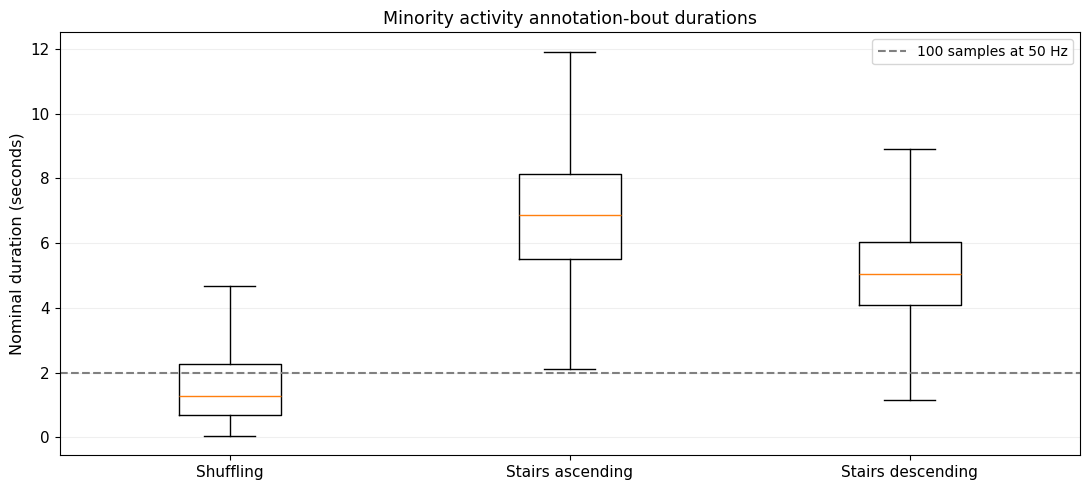

In [7]:
# =================== 06. Inspect Annotation-Bout Durations ===================

# --------------------- 1. Select Minority-Activity Bouts ---------------------
task_bouts = bouts.loc[bouts["source_code"].isin(CLASSES)].copy()
focus = task_bouts.loc[task_bouts["source_code"].isin([3, 4, 5])].copy()

# ------------------------ 2. Summarise Bout Durations ------------------------
bout_summary = task_bouts.groupby("source_code").agg(
    bouts=("samples", "size"),
    median_duration_s=("nominal_duration_seconds", "median"),
    mean_duration_s=("nominal_duration_seconds", "mean"),
    short_bouts=("shorter_than_window", "sum"),
    contributors=("subject_id", "nunique"),
).reindex(CLASSES)
bout_summary["activity"] = [ACTIVITY_NAMES[c] for c in CLASSES]
bout_summary["short_bout_pct"] = bout_summary["short_bouts"] / bout_summary["bouts"] * 100

display(bout_summary.reset_index()[[
    "source_code", "activity", "bouts", "contributors",
    "median_duration_s", "mean_duration_s", "short_bouts", "short_bout_pct"
]].round(3))

# -------------------- 3. Visualise Minority Bout Lengths ---------------------
fig, ax = plt.subplots(figsize=(11, 5))
values = [
    focus.loc[focus["source_code"] == c, "nominal_duration_seconds"]
    for c in [3, 4, 5]
]
ax.boxplot(values, tick_labels=[ACTIVITY_NAMES[c] for c in [3, 4, 5]],
           showfliers=False)

ax.axhline(2, linestyle="--", color="gray", label="100 samples at 50 Hz")
ax.set(title="Minority activity annotation-bout durations",
       ylabel="Nominal duration (seconds)")
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "20_minority_annotation_bout_durations.png")
plt.show()


**07. Reconcile Candidate-Window Rejections**

Count label impurity, timestamp discontinuity and their overlap as mutually exclusive rejection categories. Avoid double-counting candidates that violate both checks. Timestamp irregularities warrant inspection but do not alone prove corrupted measurements.

,decision,windows,share_pct
0,retained_pure_time_safe,144105,90.01
1,rejected_label_only,14459,9.03
2,rejected_time_only,397,0.25
3,rejected_both,1129,0.71


,subject_id,candidate_windows,rejected_label_only,rejected_time_only,rejected_both,nonpositive_intervals,long_intervals,median_positive_interval_seconds,rejection_pct
21,S030,4918,1509,39,35,0,39,0.02,32.188
22,S031,5390,936,3,40,0,23,0.02,18.163
27,S037,4126,610,8,40,0,26,0.02,15.948
14,S022,6751,876,26,93,0,63,0.02,14.739
3,S010,7031,930,11,13,0,13,0.02,13.568
5,S013,7380,832,29,68,0,54,0.02,12.588
6,S014,7328,791,28,100,0,69,0.02,12.541
10,S018,6444,633,22,62,0,44,0.02,11.127
24,S034,3763,384,2,26,0,14,0.02,10.949
1,S008,8378,740,8,66,0,38,0.02,9.716


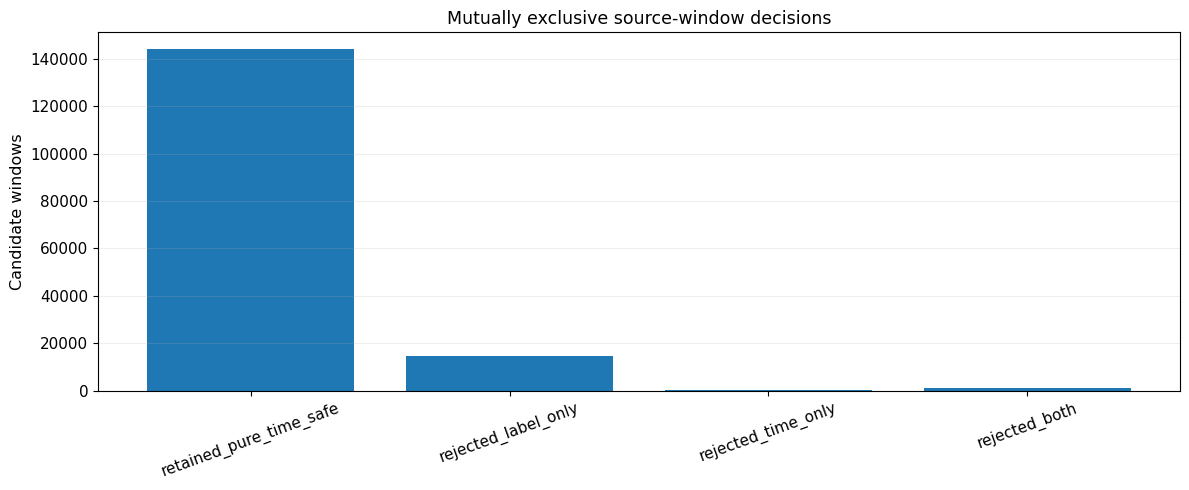

In [8]:
# ================= 07. Reconcile Candidate-Window Rejections =================

# ----------------- 1. Audit Window Acceptance and Rejection ------------------
reasons = [
    "retained_pure_time_safe", "rejected_label_only",
    "rejected_time_only", "rejected_both"
]
reason_summary = pd.DataFrame({
    "decision": reasons,
    "windows": [int(overview[name].sum()) for name in reasons]
})

# -------------- 2. Examine Participant-Level Rejection Patterns --------------
reason_summary["share_pct"] = (
    reason_summary["windows"] / overview["candidate_windows"].sum() * 100
)

display(reason_summary.round(2))
per_subject_rejection = overview[[
    "subject_id", "candidate_windows",
    "rejected_label_only", "rejected_time_only", "rejected_both",
    "nonpositive_intervals", "long_intervals",
    "median_positive_interval_seconds"
]].copy()
per_subject_rejection["rejection_pct"] = (
    (per_subject_rejection[["rejected_label_only",
      "rejected_time_only", "rejected_both"]].sum(axis=1))
    / per_subject_rejection["candidate_windows"] * 100
)

display(per_subject_rejection.sort_values("rejection_pct", ascending=False).round(3))

# ---------------------- 3. Visualise Rejection Reasons -----------------------
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(reason_summary["decision"], reason_summary["windows"])
ax.set(title="Mutually exclusive source-window decisions", ylabel="Candidate windows")
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "20_source_window_rejection_reasons.png")
plt.show()


**08. Audit Label-Independent Sampling Caps**

Compare full eligible Development windows with evenly spaced per-participant caps of 250, 500 and 1,000. This separately sampled 1,000-cap policy differs from the strictly nested training expansion used in later stages. Report both retained windows and remaining participant support by class.

policy,full,cap_250,cap_500,cap_1000
label,,,,
1,26979,1844,3591,7115
2,6305,515,1028,2050
3,1946,93,219,386
4,1332,101,192,375
5,1066,94,182,348
6,19218,1179,2227,4381
7,64644,2795,5599,11214
8,10907,580,1163,2332


policy,full,cap_250,cap_500,cap_1000
Walking,100.0,6.83,13.31,26.37
Running,100.0,8.17,16.30,32.51
Shuffling,100.0,4.78,11.25,19.84
Stairs ascending,100.0,7.58,14.41,28.15
Stairs descending,100.0,8.82,17.07,32.65
Standing,100.0,6.13,11.59,22.80
Sitting,100.0,4.32,8.66,17.35
Lying,100.0,5.32,10.66,21.38


policy,full,cap_250,cap_500,cap_1000
Walking,29,29,29,29
Running,19,19,19,19
Shuffling,28,22,26,27
Stairs ascending,26,24,24,25
Stairs descending,25,22,25,25
Standing,29,29,29,29
Sitting,28,28,28,28
Lying,23,23,23,23


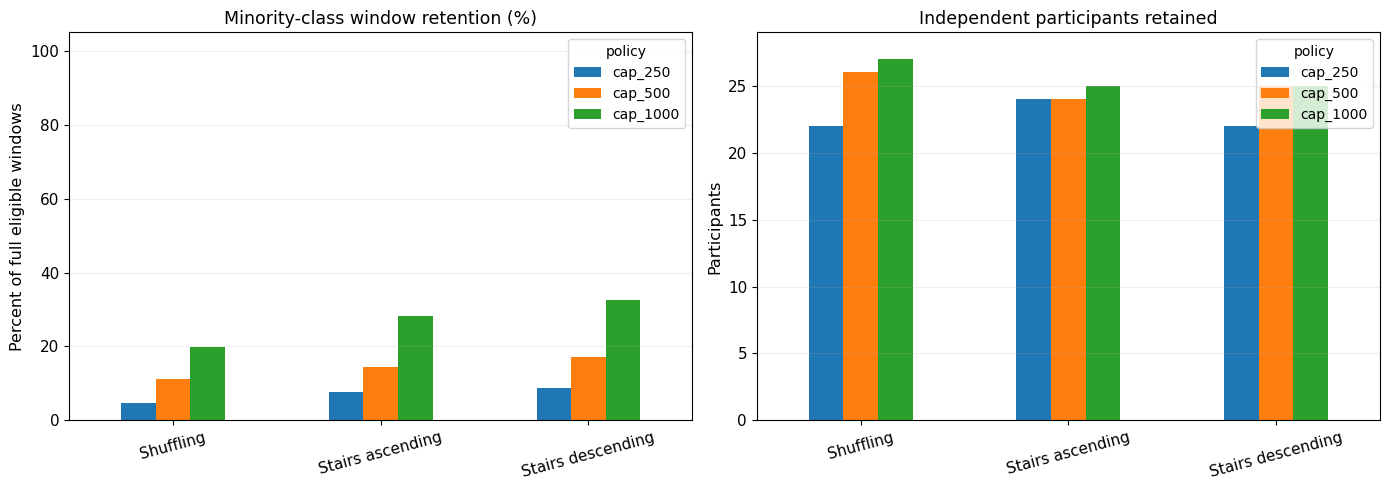

In [9]:
# ================= 08. Audit Label-Independent Sampling Caps =================

# ----------------- 1. Compare Label-Blind Sampling Policies ------------------
selected, per_subject, cap_counts = audit_temporal_sampling(
    metadata=metadata, caps=(250, 500, 1000),
    classes=CLASSES, forbidden_subjects=RESERVED_TEST,  # Prohibit sampling from the protected Test subjects.
)
cap_order = ["full", "cap_250", "cap_500", "cap_1000"]
count_table = cap_counts.pivot(
    index="label", columns="policy", values="windows"
).reindex(index=CLASSES, columns=cap_order).astype(int)

# ---------------------- 2. Calculate Activity Retention ----------------------
retention = count_table.div(count_table["full"], axis=0) * 100
retention.index = [ACTIVITY_NAMES[c] for c in CLASSES]

display(count_table)
display(retention.round(2))
support_table = selected.groupby(["label", "policy"])["subject_id"].nunique().unstack(
    fill_value=0
).reindex(index=CLASSES, columns=cap_order, fill_value=0).astype(int)
support_table.index = [ACTIVITY_NAMES[c] for c in CLASSES]

display(support_table)

# ------------------- 3. Visualise Minority-Class Retention -------------------
minority_names = [ACTIVITY_NAMES[c] for c in (3, 4, 5)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

retention.loc[minority_names, ["cap_250","cap_500","cap_1000"]].plot.bar(
    ax=axes[0], rot=15, title="Minority-class window retention (%)"
)

support_table.loc[minority_names, ["cap_250","cap_500","cap_1000"]].plot.bar(
    ax=axes[1], rot=15, title="Independent participants retained"
)
axes[0].set(ylabel="Percent of full eligible windows", ylim=(0, 105))
axes[1].set(ylabel="Participants", ylim=(0, 29))
for ax in axes:
    ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
save_figure(fig, output_dir / "20_sampling_minority_coverage.png")
plt.show()


**09. Inspect Raw Accelerometer Channels and Example Windows**

Summarise six-axis distributions and inspect selected two-second windows for Walking, Shuffling and both stair activities. Preserve source participant IDs and window locations. Unusual ranges, repeated values or low variance may merit investigation but do not establish sensor failure or annotation error.

,recordings,median_std,median_absolute_p99,largest_absolute_max,smallest_minimum,mean_repeated_adjacent_pct,nonfinite_samples
channel,,,,,,,
back_x,29,0.3087,1.4921,2.2917,-8.0000,9.6374,0
back_y,29,0.1742,0.7695,6.4919,-4.3076,9.0738,0
back_z,29,0.3344,0.9692,4.9095,-6.5745,8.6366,0
thigh_x,29,0.4834,1.9491,7.9998,-8.0000,8.8889,0
thigh_y,29,0.2919,0.9985,7.9998,-7.9973,6.6849,0
thigh_z,29,0.5845,1.3595,7.9998,-8.4062,6.0354,0


,subject_id,channel,raw_samples,nonfinite_samples,minimum,maximum,mean,std,absolute_p99,repeated_adjacent_pct
156,S036,back_x,204993,0,-2.0596,-0.0449,-0.8799,0.2337,1.2427,45.6510
157,S036,back_y,204993,0,-1.3193,1.2686,-0.0031,0.1306,0.3484,44.4930
146,S034,back_z,188202,0,-1.1296,0.8943,-0.0433,0.3619,0.8594,41.6634
144,S034,back_x,188202,0,-1.9331,-0.0974,-0.9043,0.2678,1.3293,41.4164
145,S034,back_y,188202,0,-0.6152,0.8059,0.0644,0.0688,0.2688,41.4084
147,S034,thigh_x,188202,0,-4.6484,0.6843,-0.5857,0.4834,1.5730,40.2060
159,S036,thigh_x,204993,0,-3.9778,1.5496,-0.6009,0.3668,1.6438,39.5347
141,S033,thigh_x,201688,0,-8.0000,4.9785,-0.6302,0.6133,2.8085,39.1190
158,S036,back_z,204993,0,-1.5344,0.9431,-0.0906,0.4393,0.8748,38.4888
139,S033,back_y,201688,0,-1.9355,2.5090,0.0337,0.1434,0.6028,38.1180


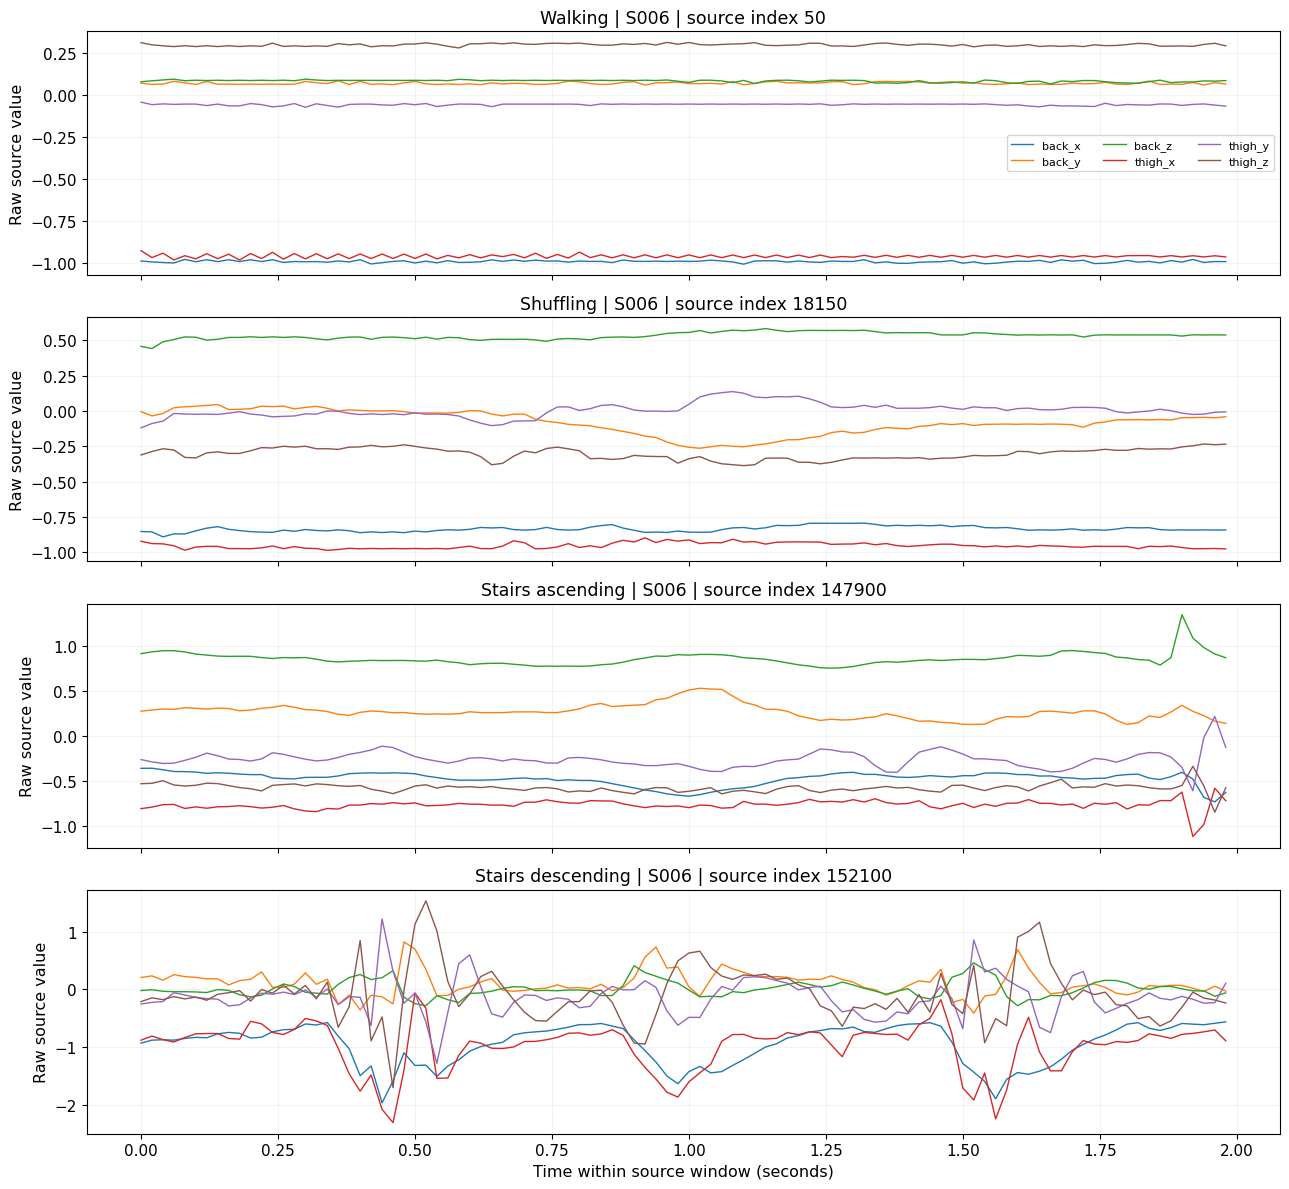

In [10]:
# ======== 09. Inspect Raw Accelerometer Channels and Example Windows =========

# ------------------ 1. Inspect Sensor Ranges and Continuity ------------------
channel_summary = channels.groupby("channel").agg(
    recordings=("subject_id", "nunique"),
    median_std=("std", "median"),
    median_absolute_p99=("absolute_p99", "median"),
    largest_absolute_max=("maximum", "max"),
    smallest_minimum=("minimum", "min"),
    mean_repeated_adjacent_pct=("repeated_adjacent_pct", "mean"),
    nonfinite_samples=("nonfinite_samples", "sum"),
)

display(channel_summary.round(4))
display(channels.sort_values("repeated_adjacent_pct", ascending=False).head(12).round(4))

# ---------------- 2. Visualise Original Accelerometer Signals ----------------
chosen_codes = [1, 3, 4, 5]

fig, axes = plt.subplots(len(chosen_codes), 1, figsize=(13, 12), sharex=True)
for ax, code in zip(axes, chosen_codes):
    item = examples.get(code)
    if item is None:
        ax.text(.5, .5, "No eligible source window", ha="center", va="center")
        continue
    for index, name in enumerate(item["channel_names"]):
        ax.plot(np.arange(item["signals"].shape[1]) / 50,
                item["signals"][index], label=name, linewidth=1)
    ax.set_title(f'{ACTIVITY_NAMES[code]} | {item["subject_id"]} | '
                 f'source index {item["start_index"]}')
    ax.set_ylabel("Raw source value")
    ax.grid(alpha=0.15)

axes[0].legend(ncol=3, fontsize=8)
axes[-1].set_xlabel("Time within source window (seconds)")
fig.tight_layout()
save_figure(fig, output_dir / "20_acceleration_source_examples.png")
plt.show()


**10. Relate Source Findings to Earlier Model Errors**

Previous Development experiments reported pooled Shuffling F1 of 0.4957 for Random Forest, 0.0000 for standard CNN and 0.1345 for weighted CNN in Stage 13. Stage 18 recorded 27 correct Shuffling predictions among 219 held-out windows under a different 400-step protocol. These results provide context, not matched causal comparisons with the source-quality measurements in this Notebook.

In [11]:
# ============ 10. Relate Source Findings to Earlier Model Errors =============

# --------------- 1. Compare Source Findings with Model Errors ----------------
historical = pd.DataFrame([
    {"experiment": "Stage 13 (matched 3-fold)", "model": "Random Forest",
     "shuffling_f1": 0.4957, "protocol_note": "500-cap model comparison"},
    {"experiment": "Stage 13 (matched 3-fold)", "model": "Standard CNN",
     "shuffling_f1": 0.0000, "protocol_note": "500-cap model comparison"},
    {"experiment": "Stage 13 (matched 3-fold)", "model": "Weighted CNN",
     "shuffling_f1": 0.1345, "protocol_note": "500-cap model comparison"},
])

display(historical)
hypotheses = pd.DataFrame([
    {"observation": "Low retained Shuffling window volume",
     "possible_investigation": "Stratified within-Train sampling or loss ablation",
     "proof_of_cause": "Not established"},
    {"observation": "Uneven activity presence by participant",
     "possible_investigation": "Group-held-out class support and fold diagnostics",
     "proof_of_cause": "Not established"},
    {"observation": "Short annotation bouts and strict 2-second windows",
     "possible_investigation": "Sensitivity to justified window lengths",
     "proof_of_cause": "Not established"},
    {"observation": "Unknown source annotation codes",
     "possible_investigation": "Request clarification from official maintainers",
     "proof_of_cause": "Not established"},
])

display(hypotheses)

# ------------------------- 2. State Evidence Limits --------------------------
print("Models trained in Stage 20: NONE")
print("Prediction errors recomputed from raw signals: NO")


,experiment,model,shuffling_f1,protocol_note
0,Stage 13 (matched 3-fold),Random Forest,0.4957,500-cap model comparison
1,Stage 13 (matched 3-fold),Standard CNN,0.0000,500-cap model comparison
2,Stage 13 (matched 3-fold),Weighted CNN,0.1345,500-cap model comparison


,observation,possible_investigation,proof_of_cause
0,Low retained Shuffling window volume,Stratified within-Train sampling or loss ablation,Not established
1,Uneven activity presence by participant,Group-held-out class support and fold diagnostics,Not established
2,Short annotation bouts and strict 2-second win...,Sensitivity to justified window lengths,Not established
3,Unknown source annotation codes,Request clarification from official maintainers,Not established


Models trained in Stage 20: NONE
Prediction errors recomputed from raw signals: NO


**11. Source Data Quality Gate and Interpretation Boundary**

Verify Development participant identities, label accounting, eligible-window totals, mutually exclusive rejections and reserved Test exclusion. The checks establish source-accounting consistency, not independent sensor calibration, annotation correctness or external validity.

Notebook 21 subsequently implemented and checked TCN, Multi-Scale CNN, 1D-ResNet and Time-Series Transformer. Notebook 22 then compared selected configurations using a matched Development evaluation.

In [12]:
# ========= 11. Source Data Quality Gate and Interpretation Boundary ==========

# ------------------- 1. Verify Cohort and Window Integrity -------------------
assert overview["subject_id"].nunique() == len(SUBJECTS) == 29
assert not (set(raw_codes["subject_id"]) & RESERVED_TEST)
assert not (set(metadata["subject_id"]) & RESERVED_TEST)
assert set(metadata["label"].unique()).issubset(CLASSES)
decision_columns = [
    "retained_pure_time_safe", "rejected_label_only",
    "rejected_time_only", "rejected_both",
]

assert overview[decision_columns].sum(axis=1).eq(
    overview["candidate_windows"]
).all()

# ------------------- 2. Check Sampling and Sensor Evidence -------------------
assert len(metadata) == int(overview["eligible_eight_class_windows"].sum()) == 132397
assert int(coverage.to_numpy().sum()) == len(metadata)
assert count_table["full"].sum() == len(metadata)
assert int(count_table["cap_500"].sum()) == 14201
assert (retention <= 100 + 1e-8).to_numpy().all()
assert channel_summary["nonfinite_samples"].eq(0).all()
assert len(examples) == len(CLASSES)

print("" + "=" * 65)

# ----------------- 3. Quality Gate and Interpretation Limits -----------------
print("STAGE 20: MINORITY-CLASS AND DATA QUALITY ANALYSIS")
print("=" * 65)
print("Development source participants:", len(SUBJECTS))
print("Documented activity classes:", len(CLASSES))
print("Eligible 100-sample windows:", f"{len(metadata):,}")
print("Original Test subjects accessed: NO")
print("Source label preservation: PASSED")
print("Window-rejection reconciliation: PASSED")
print("Participant/class coverage audit: PASSED")
print("Sampling-cap consistency: PASSED")
print("Raw sensor descriptive checks: PASSED")
print("*" * 65)
print("Stage 20 scientific quality gate: PASSED")
print("Models trained or evaluated here: NO")
print("Independent generalisation established: NO")
print("Next stage: Stage 21 - Four Advanced Temporal Architectures")

# -------------------- 4. Export Source-Quality Research Outputs -------------
overview.to_csv(output_dir / "20_development_source_accounting.csv", index=False)
raw_codes.to_csv(output_dir / "20_raw_source_label_counts.csv", index=False)
window_codes.to_csv(output_dir / "20_accepted_window_source_codes.csv", index=False)
source_labels.to_csv(output_dir / "20_source_label_summary.csv", index=False)
excluded_codes.to_csv(output_dir / "20_excluded_source_codes.csv", index=False)
post_window.to_csv(output_dir / "20_post_window_source_labels.csv", index=False)
coverage.rename_axis("subject_id").reset_index().to_csv(
    output_dir / "20_participant_activity_counts.csv", index=False
)
fractions.rename_axis("subject_id").reset_index().to_csv(
    output_dir / "20_participant_activity_percentages.csv", index=False
)
class_summary.to_csv(output_dir / "20_activity_support_summary.csv", index=False)
bouts.to_csv(output_dir / "20_source_annotation_bouts.csv", index=False)
bout_summary.reset_index().to_csv(
    output_dir / "20_annotation_bout_summary.csv", index=False
)
reason_summary.to_csv(output_dir / "20_window_rejection_summary.csv", index=False)
per_subject_rejection.to_csv(
    output_dir / "20_participant_window_rejections.csv", index=False
)
per_subject.to_csv(output_dir / "20_sampling_subject_totals.csv", index=False)
cap_counts.to_csv(output_dir / "20_sampling_class_counts.csv", index=False)
retention.rename_axis("activity").reset_index().to_csv(
    output_dir / "20_sampling_activity_retention_pct.csv", index=False
)
support_table.rename_axis("activity").reset_index().to_csv(
    output_dir / "20_sampling_participant_support.csv", index=False
)
channels.to_csv(output_dir / "20_sensor_channel_descriptives.csv", index=False)
channel_summary.rename_axis("channel").reset_index().to_csv(
    output_dir / "20_sensor_channel_summary.csv", index=False
)
historical.to_csv(output_dir / "20_historical_minority_model_results.csv", index=False)
hypotheses.to_csv(output_dir / "20_source_quality_followup_hypotheses.csv", index=False)
# The complete window metadata is included in the stage-specific ZIP.
metadata.to_csv(output_dir / "20_eligible_window_metadata.csv", index=False)
print("Saved Development source-quality tables in:", output_dir)

download_outputs_from_colab(folder="wearable_activity_recognition/output", stage="20")

STAGE 20: MINORITY-CLASS AND DATA QUALITY ANALYSIS
Development source participants: 29
Documented activity classes: 8
Eligible 100-sample windows: 132,397
Original Test subjects accessed: NO
Source label preservation: PASSED
Window-rejection reconciliation: PASSED
Participant/class coverage audit: PASSED
Sampling-cap consistency: PASSED
Raw sensor descriptive checks: PASSED
*****************************************************************
Stage 20 scientific quality gate: PASSED
Models trained or evaluated here: NO
Independent generalisation established: NO
Next stage: Stage 21 - Four Advanced Temporal Architectures
Saved Development source-quality tables in: /content/human-movement-intelligence/wearable_activity_recognition/output
------------------------------------------------------------------------
Notebook stage: 20
Files packaged: 28
  + 20_acceleration_source_examples.png
  + 20_accepted_window_source_codes.csv
  + 20_activity_support_summary.csv
  + 20_activity_window_and_subj